# Task 5 - Account Security Monitoring (Unsupervised Anomaly Detection, metric: F3 macro)

CPE342 Karena Player Intelligence System

There is **no train set and no labels**, so everything is unsupervised and fitted on the unlabeled `test.csv` features (no labels are involved).

> **Caution (rules):** because task 5 has no train set, every fitted step (scaler, PCA, GMM, IsolationForest, threshold) necessarily uses `test.csv`. The TA's rule is *"every prediction parameter must be computable without seeing the test set"*, so confirm with the TA that this is acceptable for task 5, and do not tune the flag rate from leaderboard scores.

**Update (domain-driven version):** the problem statement names three threats - *account theft*, *bot farms* and *VPN regional-price abuse*. Section 5.3 builds one detector per threat from domain features, uses the 4 binary flags only as soft evidence, and chooses between variants with **synthetic injected anomalies** (never with the leaderboard score).

## 1. Import Libraries & Configuration

In [1]:
import os, re, warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.mixture import GaussianMixture
from sklearn.metrics import fbeta_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import RobustScaler
warnings.filterwarnings("ignore")

SEED = 42
QUICK = os.environ.get("QUICK") == "1"
ROOT = Path.cwd()
OUT = ROOT / ("outputs_quick" if QUICK else "outputs"); (OUT / "models").mkdir(parents=True, exist_ok=True)
DATA = ROOT / "task5" if (ROOT / "task5" / "test.csv").exists() else ROOT   # run from repo root or from inside task5/
FLAGS = ["password_changed", "vpn_usage", "suspicious_login_time", "mass_item_sale"]
N_EST = 100 if QUICK else 300       # trees per Isolation Forest in section 5.3 / 6
CONTAMINATION = 0.10      # FINAL fraction of accounts to flag; chosen in section 5.4 (prevalence-robust F3), not tuned on the leaderboard
SELECT_RATE = 0.05        # reference flag rate used only to compare the detector variants in section 5.3

## 2. Load Data

In [2]:
test = pd.read_csv(DATA / "test.csv")
df = test.drop(columns=["player_id"])
print(f"Test shape: {test.shape} (no train set, no labels)")
test.head()

Test shape: (25889, 123) (no train set, no labels)


,player_id,login_count_1,login_count_2,login_count_3,login_count_4,login_lat_1,login_lon_1,login_lat_2,login_lon_2,login_lat_3,...,guild_changes_1,guild_changes_2,guild_changes_3,guild_changes_4,account_age_days,behavior_stability,password_changed,vpn_usage,suspicious_login_time,mass_item_sale
0,P024743,67.238336,27.598368,38.114171,45.320790,-55.660805,47.357425,-55.442687,46.861868,-55.882950,...,1.0,1.0,2.0,1.0,1027.683779,0.232040,0.0,0.0,0.0,1.0
1,P005319,21.039249,28.153000,20.788758,20.483913,44.210837,26.034926,43.930301,26.515108,43.442722,...,1.0,NaN,2.0,1.0,1450.873210,0.918705,0.0,1.0,0.0,0.0
2,P014970,90.268461,109.156193,96.764974,96.542496,37.371864,33.819993,37.351600,33.503336,37.044372,...,0.0,-1.0,-1.0,0.0,611.275151,0.764911,0.0,0.0,0.0,0.0
3,P003275,29.880876,28.448716,24.296107,24.403403,48.026437,-119.863672,47.992586,-118.485494,48.123361,...,2.0,1.0,2.0,2.0,404.103143,0.712205,0.0,0.0,0.0,0.0
4,P009022,62.283808,73.703985,48.331688,71.803417,39.647200,154.007807,39.675523,154.225136,38.851983,...,0.0,0.0,0.0,1.0,1091.671684,0.896939,0.0,0.0,0.0,0.0


## 3. Exploratory Data Analysis (EDA)

columns with missing values: 122 | max missing %: 5.3


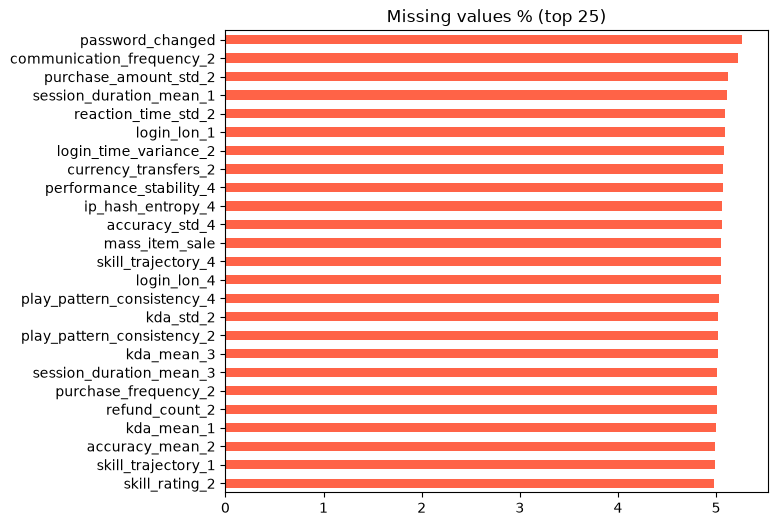

In [3]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
print("columns with missing values:", int((miss > 0).sum()), "| max missing %:", round(miss.max(), 1))
miss[miss > 0].head(25).sort_values().plot(kind="barh", color="tomato", figsize=(7, 6), title="Missing values % (top 25)")
plt.show()

flag rates: {'password_changed': 0.06, 'vpn_usage': 0.159, 'suspicious_login_time': 0.051, 'mass_item_sale': 0.029} | any flag: 25.4%


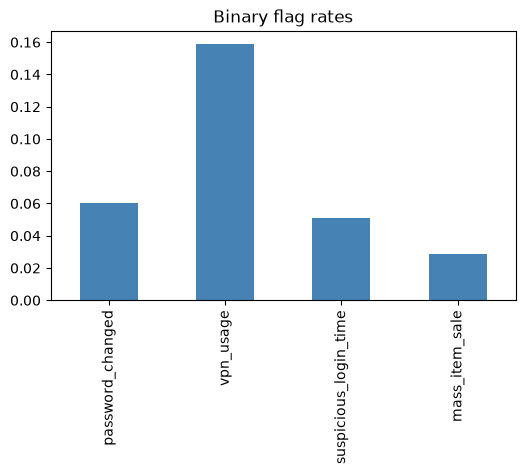

                       password_changed  vpn_usage  suspicious_login_time  \
password_changed                   1.00       0.01                   -0.0   
vpn_usage                          0.01       1.00                   -0.0   
suspicious_login_time             -0.00      -0.00                    1.0   
mass_item_sale                     0.17       0.00                    0.0   

                       mass_item_sale  
password_changed                 0.17  
vpn_usage                        0.00  
suspicious_login_time            0.00  
mass_item_sale                   1.00  
accounts with >=2 flags: observed 2.69% vs 2.39% expected if flags were independent


In [4]:
rates = df[FLAGS].mean()
print("flag rates:", rates.round(3).to_dict(), "| any flag:", f"{(df[FLAGS].fillna(0).sum(axis=1) > 0).mean():.1%}")
rates.plot(kind="bar", color="steelblue", figsize=(6, 3.5), title="Binary flag rates"); plt.show()
c = df[FLAGS].fillna(0).corr().round(2); print(c)

# do flags co-occur more than chance? (if they were independent noise, >=2 flags would be rarer)
n_flags = df[FLAGS].fillna(0).sum(axis=1)
dist = np.array([1.0])
for p_ in df[FLAGS].fillna(0).mean().values:
    dist = np.convolve(dist, [1 - p_, p_])
print(f"accounts with >=2 flags: observed {(n_flags >= 2).mean():.2%} vs {dist[2:].sum():.2%} expected if flags were independent")

## 4. Data Preprocessing (baseline features)

Each metric has 4 consecutive periods (`_1.._4`); they are summarised as **mean, std and slope (last - first)**. These baseline features (and the IsolationForest / PCA / GMM comparison in section 5.1-5.2) are kept as a reference. In this baseline the 4 binary flags are *not* model inputs because they are noisy (the current rule system has a 60 % false-positive rate); section 5.3 tests whether using them as soft evidence helps.

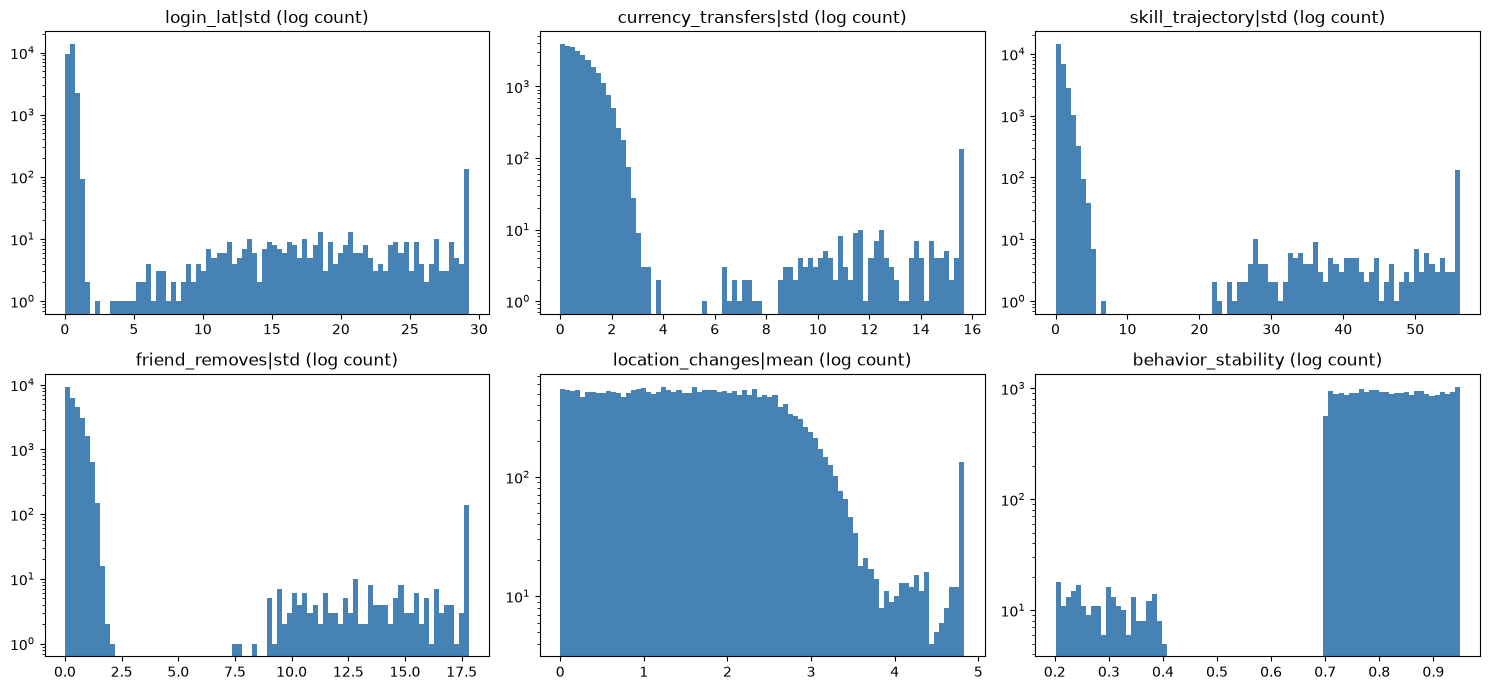

small separate bumps hint at distinct anomalous sub-populations


In [5]:
def aggregate_periods(df):
    feats = {}
    bases = sorted({re.sub(r"_[1-4]$", "", c) for c in df.columns if re.search(r"_[1-4]$", c)})
    for b in bases:
        M_ = df[[f"{b}_{i}" for i in range(1, 5)]]
        feats[f"{b}|mean"], feats[f"{b}|std"] = M_.mean(axis=1), M_.std(axis=1)
        feats[f"{b}|slope"] = M_[f"{b}_4"] - M_[f"{b}_1"]
    for c in ["account_age_days", "behavior_stability"]:
        feats[c] = df[c]
    return pd.DataFrame(feats)

F = aggregate_periods(df)
key = ["login_lat|std", "currency_transfers|std", "skill_trajectory|std", "friend_removes|std", "location_changes|mean", "behavior_stability"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.flat, key):
    lo, hi = F[c].quantile([0.0, 0.995])
    ax.hist(F[c].dropna().clip(lo, hi), bins=80, color="steelblue"); ax.set_yscale("log"); ax.set_title(c + " (log count)")
plt.tight_layout(); plt.show()
print("small separate bumps hint at distinct anomalous sub-populations")

In [6]:
F = F.fillna(F.median())
Z = np.clip(RobustScaler().fit_transform(F), -8, 8)
print(f"period-aggregated features: {F.shape[1]}")

period-aggregated features: 89


## 5. Model Training & Validation

### 5.1 Structure discovery (PCA + Gaussian mixture)
A mixture model on the first 8 principal components reveals small, clearly separated sub-populations. They serve as a **sanity-check reference** for the detectors (there are no true labels).

cluster 1: n=517 (2.0%) | most shifted: {'login_lon|std': 6.5, 'login_lat|std': 6.5, 'location_changes|std': 6.2, 'location_changes|slope': 6.0} | flag rates: {'password_changed': 0.61, 'vpn_usage': 0.52, 'suspicious_login_time': 0.07, 'mass_item_sale': 0.43}
cluster 2: n=310 (1.2%) | most shifted: {'skill_trajectory|std': 8.6, 'friend_removes|std': 8.5, 'skill_trajectory|slope': 8.4, 'friend_removes|slope': 8.4} | flag rates: {'password_changed': 0.06, 'vpn_usage': 0.15, 'suspicious_login_time': 0.04, 'mass_item_sale': 0.02}
distinct sub-populations: 827 rows = 3.2% of accounts


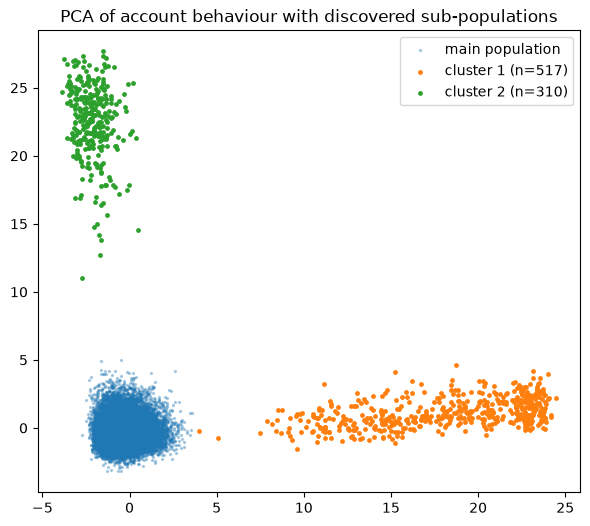

In [7]:
def top_shift(F, mask, k=6):
    return ((F[mask].mean() - F[~mask].mean()) / F.std()).abs().sort_values(ascending=False).head(k)

pca8 = PCA(8, random_state=SEED)
P = pca8.fit_transform(Z)
gmm = GaussianMixture(4, covariance_type="full", random_state=SEED, n_init=3).fit(P)
lab = gmm.predict(P)
sizes = np.bincount(lab, minlength=4)
minor = [k for k in range(4) if sizes[k] < 0.05 * len(lab)]
group = np.zeros(len(lab), dtype=bool)
for k in minor:
    m = lab == k
    group |= m
    sh = top_shift(F, m)
    print(f"cluster {k}: n={m.sum()} ({m.mean():.1%}) | most shifted: { {a: round(b, 1) for a, b in sh.head(4).items()} } | flag rates: {df.loc[m, FLAGS].mean().round(2).to_dict()}")
print(f"distinct sub-populations: {group.sum()} rows = {group.mean():.1%} of accounts")
plt.figure(figsize=(7, 6))
plt.scatter(P[~group, 0], P[~group, 1], s=2, alpha=0.3, label="main population")
for k in minor:
    plt.scatter(P[lab == k, 0], P[lab == k, 1], s=6, label=f"cluster {k} (n={sizes[k]})")
plt.legend(); plt.title("PCA of account behaviour with discovered sub-populations"); plt.show()

### 5.2 Compare detectors: how much of the discovered groups lies in each detector's top 5 % of scores?
(Caveat: the reference groups come from the same data, so this is a sanity check, not a leaderboard estimate.)

PCA reconstruction     0.530
IF+PCA rank-average    0.759
IsolationForest        1.000
Gaussian density       1.000
dtype: float64


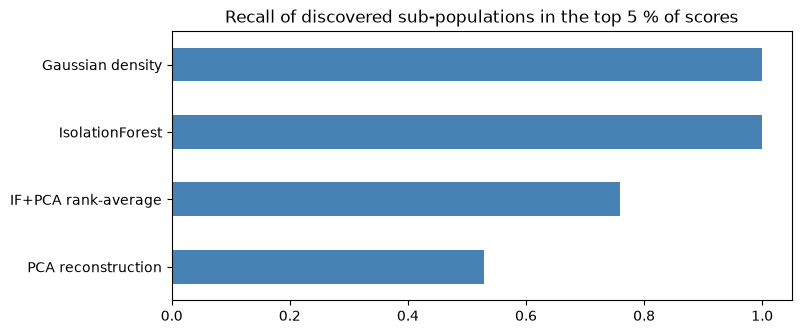

Best detector: IsolationForest


In [8]:
iso = IsolationForest(n_estimators=100 if QUICK else 600, max_samples=1024, random_state=SEED, n_jobs=-1).fit(Z)
s_iso = -iso.score_samples(Z)
pca95 = PCA(n_components=0.95, random_state=SEED).fit(Z)
s_pca = ((Z - pca95.inverse_transform(pca95.transform(Z))) ** 2).sum(axis=1)
s_gmm = -GaussianMixture(1, covariance_type="full", random_state=SEED).fit(P).score_samples(P)
cands = {"IsolationForest": s_iso, "PCA reconstruction": s_pca, "Gaussian density": s_gmm,
         "IF+PCA rank-average": rankdata(s_iso) + rankdata(s_pca)}
n_top = int(0.05 * len(Z))
recall = {n: float(group[np.argsort(-s)[:n_top]].sum() / group.sum()) for n, s in cands.items()}
res = pd.Series(recall).sort_values()
print(res.round(3))
res.plot(kind="barh", figsize=(8, 3.5), color="steelblue", title="Recall of discovered sub-populations in the top 5 % of scores")
plt.show()
best = res.idxmax()
print("Best detector:", best)

### 5.3 Domain-driven detectors (account theft / bot farm / VPN-economy abuse)

The problem statement lists three threats, so instead of one blind detector on every feature we build one detector per threat:

| detector | what it looks for | main features |
|---|---|---|
| **theft** | someone else suddenly plays the account | geographic jump between periods, new devices, sudden change in skill / reaction / accuracy / KDA, currency cash-out, flags |
| **bot** | inhuman regularity, 24/7 activity | very low login-time / session / reaction variance, very high play-pattern consistency and activity |
| **vpn_economy** | VPN price arbitrage, economy abuse | VPN flag, IP entropy, location changes, purchase / refund / transfer / social churn |

Each group is scored by three *different kinds* of detector - **Isolation Forest** (isolation), **PCA reconstruction error** (breaks the linear correlation structure) and **k-NN distance** (low local density, cross-fitted on two halves) - converted to rank percentiles and averaged; groups are combined with *max* (anomalous in any threat).

**How the variant is chosen (no leaderboard involved):** synthetic anomalies are injected into the real data and F3 (macro) of the flagged top 5 % (reference rate `SELECT_RATE`) is measured in **four scenarios**: flags informative, flags uninformative, *weak* anomalies (60 % strength) and a **generic unseen type** (3 random metrics shifted by 3 SD - not used to design any feature group). The variant with the best average F3 is used and its worst-case is reported. Caveat: injections reflect our own assumptions, so absolute numbers are optimistic; they are used to **compare variants and catch regressions**, not to predict the final score.

In [9]:
def great_circle_deg(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return np.degrees(2 * np.arcsin(np.sqrt(np.clip(a, 0, 1))))


def build_features(df):
    feats = {}
    bases = sorted({re.sub(r"_[1-4]$", "", c) for c in df.columns if re.search(r"_[1-4]$", c)})
    for b in bases:
        M_ = df[[f"{b}_{i}" for i in range(1, 5)]]
        feats[f"{b}|mean"], feats[f"{b}|std"] = M_.mean(axis=1), M_.std(axis=1)
        feats[f"{b}|slope"] = M_[f"{b}_4"] - M_[f"{b}_1"]
        feats[f"{b}|jump"] = M_.diff(axis=1).abs().max(axis=1)          # largest period-to-period change
    jumps = np.column_stack([great_circle_deg(df[f"login_lat_{i}"], df[f"login_lon_{i}"],
                                              df[f"login_lat_{i + 1}"], df[f"login_lon_{i + 1}"]) for i in range(1, 4)])
    feats["geo_jump_max"], feats["geo_jump_mean"] = np.nanmax(jumps, axis=1), np.nanmean(jumps, axis=1)
    for c in ["account_age_days", "behavior_stability"]:
        feats[c] = df[c]
    for c in FLAGS:
        feats[f"flag|{c}"] = df[c].fillna(0)
    feats["flag_count"] = df[FLAGS].fillna(0).sum(axis=1)
    return pd.DataFrame(feats)


def prepare(df):
    X = build_features(df)
    return X.fillna(X.median())


GROUP_COLS = {
    "theft": ["geo_jump_max", "geo_jump_mean", "location_changes|mean", "location_changes|jump", "device_count|mean", "device_count|jump",
              "ip_hash_entropy|mean", "ip_hash_entropy|jump", "skill_rating|jump", "skill_rating|slope", "skill_trajectory|jump",
              "reaction_time_mean|jump", "accuracy_mean|jump", "kda_mean|jump", "login_time_variance|jump", "currency_transfers|jump",
              "currency_transfers|mean", "behavior_stability", "flag|password_changed", "flag|suspicious_login_time", "flag|mass_item_sale", "flag_count"],
    "bot": ["login_time_variance|mean", "login_time_variance|std", "session_duration_std|mean", "session_duration_mean|mean",
            "reaction_time_std|mean", "reaction_time_mean|mean", "accuracy_std|mean", "kda_std|mean", "play_pattern_consistency|mean",
            "performance_stability|mean", "activity_level|mean", "login_count|mean", "communication_frequency|mean", "friend_adds|mean",
            "behavior_stability", "account_age_days"],
    "vpn_economy": ["flag|vpn_usage", "flag|mass_item_sale", "flag_count", "ip_hash_entropy|mean", "location_changes|mean", "geo_jump_mean",
                    "purchase_frequency|mean", "purchase_amount_mean|mean", "purchase_amount_std|mean", "refund_count|mean",
                    "currency_transfers|mean", "friend_removes|mean", "guild_changes|mean"],
}
F_new = prepare(df)
missing_cols = [c for g in GROUP_COLS.values() for c in g if c not in F_new.columns]
assert not missing_cols, missing_cols
print(f"new feature table: {F_new.shape[1]} columns |", {g: len(c) for g, c in GROUP_COLS.items()})


def pct(s):
    return rankdata(s) / len(s)


def scaled(F, cols):
    return np.clip(RobustScaler().fit_transform(F[cols]), -8, 8)


def fit_if(F, cols, seed, n_est):
    X = scaled(F, cols)
    m = IsolationForest(n_estimators=n_est, max_samples=1024, random_state=seed, n_jobs=-1).fit(X)
    return pct(-m.score_samples(X)), m


def score_pca(X, seed):
    p = PCA(n_components=0.9, random_state=seed).fit(X)
    return ((X - p.inverse_transform(p.transform(X))) ** 2).sum(axis=1)


def score_knn(X, seed, k=10):
    # cross-fitted: rows of one half are scored against the other half (no row is its own neighbour)
    perm = np.random.default_rng(seed).permutation(len(X))
    a, b = perm[: len(X) // 2], perm[len(X) // 2:]
    s = np.zeros(len(X))
    for ref, qry in ((a, b), (b, a)):
        d, _ = NearestNeighbors(n_neighbors=k, n_jobs=-1).fit(X[ref]).kneighbors(X[qry])
        s[qry] = d[:, -1]
    return s


def detector_scores(F, seed, n_est):
    """Rank-percentile scores for (kind, flags_used, group). PCA / kNN are only computed without flags."""
    S, models = {}, {}
    for use_flags in (True, False):
        for g in [*GROUP_COLS, "global"]:
            cols = list(F.columns) if g == "global" else GROUP_COLS[g]
            cols = [c for c in cols if use_flags or not c.startswith("flag")]
            S[("if", use_flags, g)], models[("if", use_flags, g)] = fit_if(F, cols, seed, n_est)
            if not use_flags:
                X = scaled(F, cols)
                S[("pca", False, g)], S[("knn", False, g)] = pct(score_pca(X, seed)), pct(score_knn(X, seed))
    return S, models


VARIANTS = ["baseline: IF on old aggregates",
            "new features: global IF",
            "3 groups: max (IF)",
            "3 groups: max (IF, flags removed)",
            "3 groups: max (IF+PCA)",
            "3 groups: max (IF+kNN)",
            "3 groups: max (IF+PCA+kNN)",
            "3 groups: mean (IF+PCA+kNN)",
            "global ensemble (IF+PCA+kNN)"]


def variant_scores(S):
    G = list(GROUP_COLS)
    grp = lambda kinds, fl: np.column_stack([np.mean([S[(k, fl, g)] for k in kinds], axis=0) for g in G])
    return {VARIANTS[1]: S[("if", True, "global")],
            VARIANTS[2]: grp(["if"], True).max(axis=1),
            VARIANTS[3]: grp(["if"], False).max(axis=1),
            VARIANTS[4]: grp(["if", "pca"], False).max(axis=1),
            VARIANTS[5]: grp(["if", "knn"], False).max(axis=1),
            VARIANTS[6]: grp(["if", "pca", "knn"], False).max(axis=1),
            VARIANTS[7]: grp(["if", "pca", "knn"], False).mean(axis=1),
            VARIANTS[8]: np.mean([S[(k, False, "global")] for k in ("if", "pca", "knn")], axis=0)}


def top_rate_flags(score, rate=CONTAMINATION):
    return (score >= np.quantile(score, 1 - rate)).astype(int)


def jaccard(a, b):
    return float((a & b).sum() / max((a | b).sum(), 1))

new feature table: 125 columns | {'theft': 22, 'bot': 16, 'vpn_economy': 13}


scenario                           threats / flags informative  threats / flags uninformative  threats / weak (60 %)  generic unseen type    avg  worst
variant                                                                                                                                                
baseline: IF on old aggregates                           0.709                          0.709                  0.696                0.564  0.669  0.564
new features: global IF                                  0.720                          0.717                  0.713                0.544  0.673  0.544
3 groups: max (IF)                                       0.784                          0.729                  0.599                0.567  0.670  0.567
3 groups: max (IF, flags removed)                        0.786                          0.786                  0.651                0.576  0.700  0.576
3 groups: max (IF+PCA)                                   0.645                          

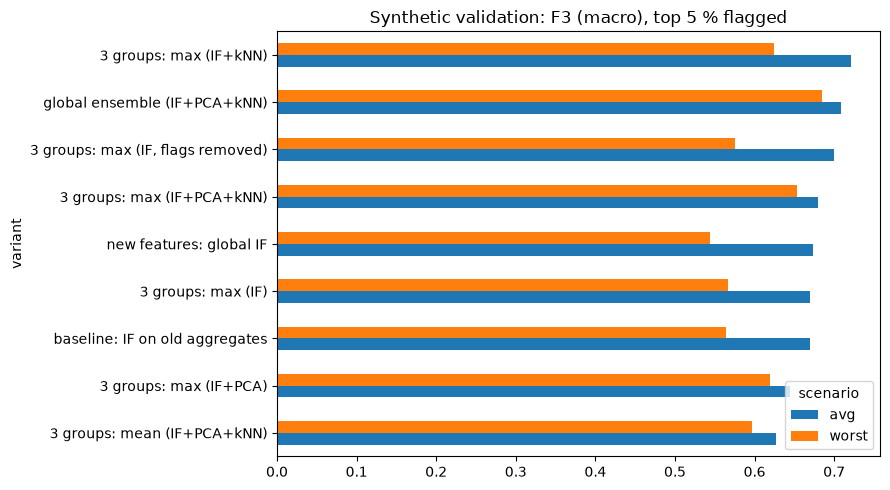

In [10]:
def inject(df, seed, rate=0.04, strength=1.0, flag_signal=True, kind="threats"):
    """Inject synthetic anomalies into a copy of df. Returns (df_syn, y). strength scales every effect."""
    rng = np.random.default_rng(seed)
    d, n, s = df.copy(), len(df), strength
    idx = rng.permutation(n)[: int(rate * n)]
    y = np.zeros(n, dtype=int); y[idx] = 1

    def setcol(col, rows, values):
        d.iloc[rows, d.columns.get_loc(col)] = values

    def blend(col, rows, target):                       # move values toward target by `strength`
        old = df[col].values[rows]
        setcol(col, rows, old + s * (target - old))

    if kind == "generic":      # unseen anomaly type: 3 random metrics shifted by +-3 SD in every period
        bases = sorted({re.sub(r"_[1-4]$", "", c) for c in df.columns if re.search(r"_[1-4]$", c)})
        for b in rng.choice(bases, 3, replace=False):
            sign = rng.choice([-1.0, 1.0], len(idx))
            for i in range(1, 5):
                setcol(f"{b}_{i}", idx, df[f"{b}_{i}"].values[idx] + sign * 3 * df[f"{b}_{i}"].std())
        return d, y

    theft, bot, vpn = np.array_split(idx, 3)
    # 1) account theft: from period 3 another person plays (other skill / reaction / accuracy / KDA / location), new device, cash-out
    donor = rng.integers(0, n, len(theft))
    for b in ["skill_rating", "reaction_time_mean", "accuracy_mean", "kda_mean", "login_lat", "login_lon"]:
        for p in (3, 4):
            blend(f"{b}_{p}", theft, df[f"{b}_{p}"].values[donor])
    for p in (3, 4):
        setcol(f"device_count_{p}", theft, df[f"device_count_{p}"].values[theft] + s * rng.integers(1, 4, len(theft)))
    setcol("currency_transfers_4", theft, df["currency_transfers_4"].values[theft] * (1 + s * rng.uniform(2, 5, len(theft))) + 5 * s)
    # 2) bot farm: inhumanly regular, always active
    for i in range(1, 5):
        for c in ["login_time_variance", "session_duration_std", "reaction_time_std"]:
            setcol(f"{c}_{i}", bot, df[f"{c}_{i}"].values[bot] * (1 - 0.7 * s))
        blend(f"play_pattern_consistency_{i}", bot, 0.97 + 0.03 * rng.random(len(bot)))
        for c in ["activity_level", "login_count"]:
            setcol(f"{c}_{i}", bot, df[f"{c}_{i}"].values[bot] * (1 + s))
    # 3) VPN price arbitrage: masked IP / jumping location, more purchases at lower amounts
    for i in range(1, 5):
        setcol(f"ip_hash_entropy_{i}", vpn, np.minimum(1, df[f"ip_hash_entropy_{i}"].values[vpn] + 0.25 * s))
        dn = rng.integers(0, n, len(vpn))
        for b in ("login_lat", "login_lon"):
            blend(f"{b}_{i}", vpn, df[f"{b}_{i}"].values[dn])
        setcol(f"purchase_frequency_{i}", vpn, df[f"purchase_frequency_{i}"].values[vpn] * (1 + s) + 0.5 * s)
        setcol(f"purchase_amount_mean_{i}", vpn, df[f"purchase_amount_mean_{i}"].values[vpn] * (1 - 0.4 * s))
    if flag_signal:            # scenario "flags informative"
        for c, pr in [("password_changed", .5), ("suspicious_login_time", .5), ("mass_item_sale", .4)]:
            setcol(c, theft, (rng.random(len(theft)) < pr).astype(float))
        setcol("vpn_usage", vpn, 1.0)
    return d, y


def f3_macro(y, flagged):
    return fbeta_score(y, flagged, beta=3, average="macro", zero_division=0)


SCENARIOS = {"threats / flags informative": dict(strength=1.0, flag_signal=True),
             "threats / flags uninformative": dict(strength=1.0, flag_signal=False),
             "threats / weak (60 %)": dict(strength=0.6, flag_signal=False),
             "generic unseen type": dict(kind="generic")}
N_SYN, N_EST_VAL = (1 if QUICK else 2), (100 if QUICK else 150)
rows = []
for scen, kw in SCENARIOS.items():
    for k in range(N_SYN):
        d_syn, y = inject(df, 100 + k, **kw)
        F_old_s = aggregate_periods(d_syn); F_old_s = F_old_s.fillna(F_old_s.median())
        S_s, _ = detector_scores(prepare(d_syn), SEED + k, N_EST_VAL)
        scs = {VARIANTS[0]: fit_if(F_old_s, list(F_old_s.columns), SEED + k, N_EST_VAL)[0], **variant_scores(S_s)}
        for name, sc_ in scs.items():
            fl = top_rate_flags(sc_, SELECT_RATE)
            rows.append({"scenario": scen, "variant": name, "F3 macro": f3_macro(y, fl), "recall": fl[y == 1].mean()})
val = pd.DataFrame(rows)
tab = val.pivot_table(index="variant", columns="scenario", values="F3 macro").loc[VARIANTS][list(SCENARIOS)]
tab["avg"], tab["worst"] = tab.mean(axis=1), tab[list(SCENARIOS)].min(axis=1)
print(tab.round(3).to_string())
best_variant = tab["avg"].idxmax()
print(f"\nBest variant (highest average F3 over {len(SCENARIOS)} scenarios): {best_variant}"
      f" | avg {tab.loc[best_variant, 'avg']:.3f} (baseline {tab.loc[VARIANTS[0], 'avg']:.3f}) | worst {tab.loc[best_variant, 'worst']:.3f}")
tab[["avg", "worst"]].sort_values("avg").plot(kind="barh", figsize=(9, 5), title="Synthetic validation: F3 (macro), top 5 % flagged")
plt.tight_layout(); plt.show()

### 5.4 Choosing the flag rate (prevalence-robust)

There is no label and the problem statement gives no anomaly share, so a single flag rate cannot be tuned. Instead, synthetic anomalies are injected at **different prevalences (2 %, 4 %, 8 %)** and F3 (macro) is measured for flag rates from 2 % to 12 %. The rate to use is the one with the smallest *worst-case regret* (the largest gap to the best rate of any prevalence).

**Result:** 10 % and 12 % are practically tied (max regret 0.035 vs 0.032, within the noise of this simulation) and both are far better than 5 % (avg F3 0.783 / 0.789 vs 0.692). **10 % is used** because it loses less if the true prevalence is low (at 2 %: F3 0.787 vs 0.764).

F3 weights recall 9x more than precision and the detectors do not rank every anomaly in the top, so flagging more than the true prevalence pays off. Caveat: the injections reflect our own assumptions; this shows that 5 % is probably too low, it does not guarantee the final score. No leaderboard score is used.

F3 (macro) of variant '3 groups: max (IF+kNN)' by flag rate (rows) and injected prevalence (columns), mean over 3 scenarios
prevalence   0.02   0.04   0.08  avg F3  worst F3  max regret
flag_rate                                                    
0.02        0.649  0.598  0.552   0.599     0.552       0.232
0.03        0.685  0.631  0.577   0.631     0.577       0.207
0.04        0.720  0.663  0.599   0.660     0.599       0.185
0.05        0.753  0.698  0.625   0.692     0.625       0.159
0.06        0.775  0.730  0.653   0.719     0.653       0.131
0.08        0.797  0.784  0.702   0.761     0.702       0.082
0.10        0.787  0.814  0.749   0.783     0.749       0.035
0.12        0.764  0.819  0.784   0.789     0.764       0.032

min-max-regret flag rate = 12% | configured CONTAMINATION = 10% | 5 % would have avg F3 0.692 vs 0.783


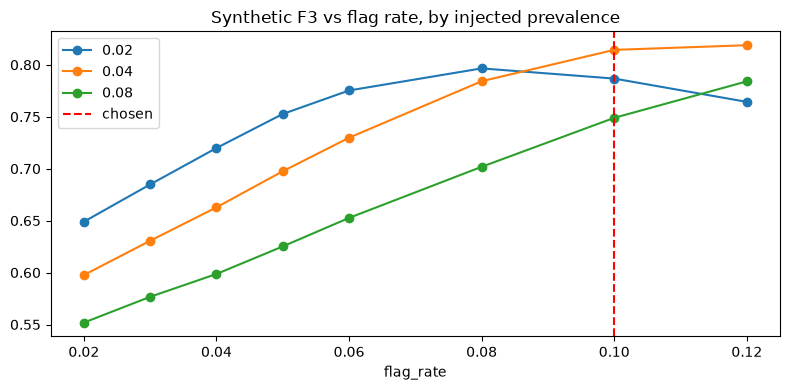

In [11]:
RATES = [0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10, 0.12]
PREVS = [0.02, 0.04, 0.08]
SCEN_54 = {k: SCENARIOS[k] for k in ("threats / flags uninformative", "threats / weak (60 %)", "generic unseen type")}


def selected_scores(d_syn, seed):
    if best_variant == VARIANTS[0]:
        Fo = aggregate_periods(d_syn); Fo = Fo.fillna(Fo.median())
        return fit_if(Fo, list(Fo.columns), seed, N_EST_VAL)[0]
    return variant_scores(detector_scores(prepare(d_syn), seed, N_EST_VAL)[0])[best_variant]


rate_rows = []
for prev in PREVS:
    for scen, kw in SCEN_54.items():
        d_syn, y = inject(df, 200, rate=prev, **kw)
        sc_ = selected_scores(d_syn, SEED)
        for r_ in RATES:
            rate_rows.append({"prevalence": prev, "scenario": scen, "flag_rate": r_, "F3": f3_macro(y, top_rate_flags(sc_, r_))})
R = pd.DataFrame(rate_rows)
byprev = R.pivot_table(index="flag_rate", columns="prevalence", values="F3", aggfunc="mean")
regret = byprev.max(axis=0) - byprev                      # gap to the best flag rate of that prevalence
summ = byprev.copy()
summ["avg F3"], summ["worst F3"], summ["max regret"] = byprev.mean(axis=1), byprev.min(axis=1), regret.max(axis=1)
print(f"F3 (macro) of variant '{best_variant}' by flag rate (rows) and injected prevalence (columns), mean over 3 scenarios")
print(summ.round(3).to_string())
rec = summ["max regret"].idxmin()
print(f"\nmin-max-regret flag rate = {rec:.0%} | configured CONTAMINATION = {CONTAMINATION:.0%} | 5 % would have avg F3 {summ.loc[0.05, 'avg F3']:.3f} vs {summ.loc[CONTAMINATION, 'avg F3']:.3f}")
byprev.plot(marker="o", figsize=(8, 4), title="Synthetic F3 vs flag rate, by injected prevalence")
plt.axvline(CONTAMINATION, color="red", ls="--", label="chosen"); plt.legend(); plt.tight_layout(); plt.show()

## 6. Final Detector, Predict & Save

F3 weights recall 9x more than precision, so more than the clearly separated groups (3.2 %) is flagged: the **top 10 %** of scores (section 5.4). The detector is the variant that won the synthetic validation in 5.3; neither the detector nor the flag rate is tuned on the leaderboard.

detector: 3 groups: max (IF+kNN)
flagged 2589 / 25889 (10.0%) | covers 99.9% of the discovered groups
  if flag rate = 3%: coverage of discovered groups 60.7%
  if flag rate = 5%: coverage of discovered groups 89.7%
  if flag rate = 8%: coverage of discovered groups 99.8%
  if flag rate = 10%: coverage of discovered groups 99.9%
  if flag rate = 12%: coverage of discovered groups 99.9%


seed stability (Jaccard of flagged sets): [0.841, 0.839]
overlap with the old baseline flags (Jaccard): 0.387
>=2 flags: 10.4% of flagged vs 1.8% of the rest


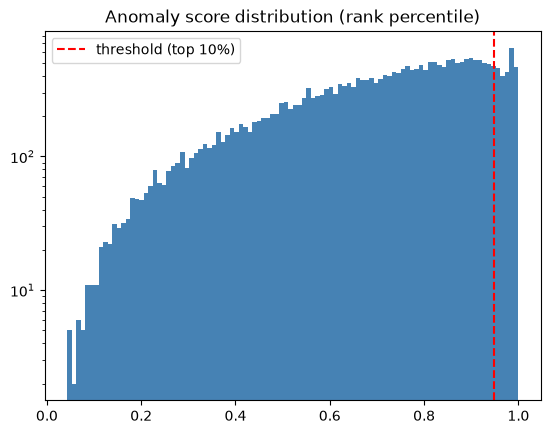

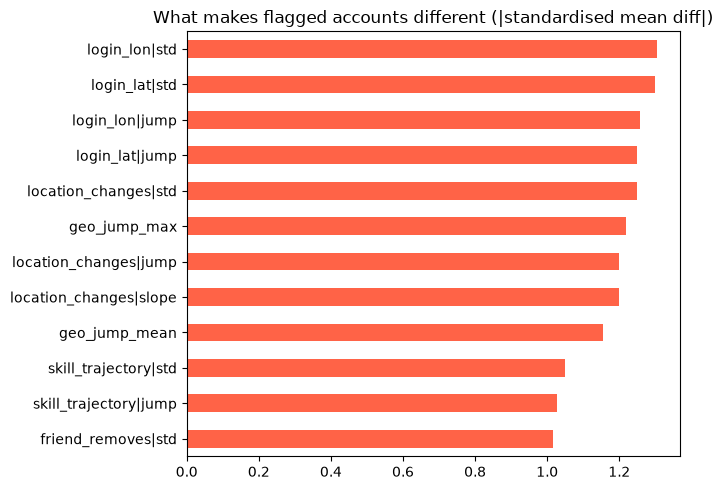

In [12]:
S_real, models_real = detector_scores(F_new, SEED, N_EST)
V_real = {VARIANTS[0]: fit_if(F, list(F.columns), SEED, N_EST)[0], **variant_scores(S_real)}
best = best_variant
score = V_real[best]
thr = np.quantile(score, 1 - CONTAMINATION)
pred = (score >= thr).astype(int)
print(f"detector: {best}")
print(f"flagged {pred.sum()} / {len(pred)} ({pred.mean():.1%}) | covers {group[pred == 1].sum() / group.sum():.1%} of the discovered groups")
for rate in (0.03, 0.05, 0.08, 0.10, 0.12):
    t = np.quantile(score, 1 - rate)
    print(f"  if flag rate = {rate:.0%}: coverage of discovered groups {group[score >= t].sum() / group.sum():.1%}")

# stability: do other random seeds flag (almost) the same accounts?
others = [top_rate_flags(variant_scores(detector_scores(F_new, s, N_EST)[0])[best]).astype(bool) for s in (7, 21)]
print("seed stability (Jaccard of flagged sets):", [round(jaccard(pred.astype(bool), o), 3) for o in others])
print("overlap with the old baseline flags (Jaccard):", round(jaccard(pred.astype(bool), top_rate_flags(V_real[VARIANTS[0]]).astype(bool)), 3))
nf = df[FLAGS].fillna(0).sum(axis=1)
print(f">=2 flags: {(nf[pred == 1] >= 2).mean():.1%} of flagged vs {(nf[pred == 0] >= 2).mean():.1%} of the rest")

plt.hist(score, bins=100, color="steelblue"); plt.axvline(thr, color="red", ls="--", label=f"threshold (top {CONTAMINATION:.0%})")
plt.yscale("log"); plt.legend(); plt.title("Anomaly score distribution (rank percentile)"); plt.show()
top_shift(F_new, pred == 1, 12).sort_values().plot(kind="barh", figsize=(7, 5), color="tomato",
                                                    title="What makes flagged accounts different (|standardised mean diff|)")
plt.tight_layout(); plt.show()

In [13]:
out = pd.DataFrame({"id": [f"ANS{i + 1:05d}" for i in range(len(pred))], "pred": pred, "score": score})
out.to_csv(OUT / "task5_pred.csv", index=False)
joblib.dump({"detector": best, "iso_baseline": iso, "models": models_real, "group_cols": GROUP_COLS, "pca8": pca8, "gmm": gmm, "threshold": thr, "features": list(F_new.columns)},
            OUT / "models" / "task5_model.joblib")
print("saved", OUT / "task5_pred.csv", "and", OUT / "models" / "task5_model.joblib")

saved D:\CPE3TERM1\CPE342 ML\Lab\cpe342-kaggle-main\outputs\task5_pred.csv and D:\CPE3TERM1\CPE342 ML\Lab\cpe342-kaggle-main\outputs\models\task5_model.joblib
